### Imports
---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.ticker import FormatStrFormatter, MultipleLocator

### Loading the clean datasets
---

In [2]:
BASE = Path("data/ml-32m/clean")

ratings = pd.read_parquet(BASE / "ratings.parquet")
movies = pd.read_parquet(BASE / "movies.parquet")
tags = pd.read_parquet(BASE / "tags.parquet")
links = pd.read_parquet(BASE / "links.parquet")

### Top 10 best movies (with a min of 1000 reviews)
---

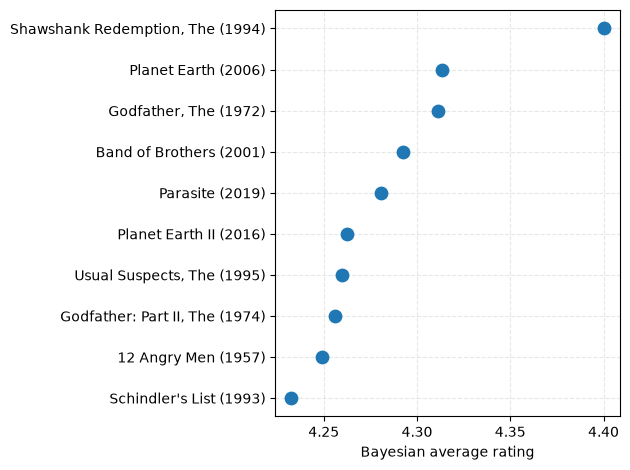

In [4]:
stats = ratings.groupby("movie_id")["rating"].agg(
    mean_rating="mean",
    count="count"
).reset_index()

stats = stats.merge(
    movies,
    on="movie_id", 
    how="left", 
    validate="one_to_one"
)

# prior strength: "virtual" ratings sitting at the global mean
C = 500

stats["total"] = (
    stats["mean_rating"]
    .astype("float64") * stats["count"]
)

global_mean = stats["total"].sum() / stats["count"].sum()

stats["bayes_rating"] = (
    (C * global_mean + stats["total"]) / 
    (C + stats["count"])
)

top_10 = stats.nlargest(10, "bayes_rating").copy()

fig, ax = plt.subplots()
ax.scatter(top_10["bayes_rating"], top_10["title"], s=80, zorder=3)
ax.invert_yaxis()
ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.set_xlabel("Bayesian average rating")
ax.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### Ratings distribution
---

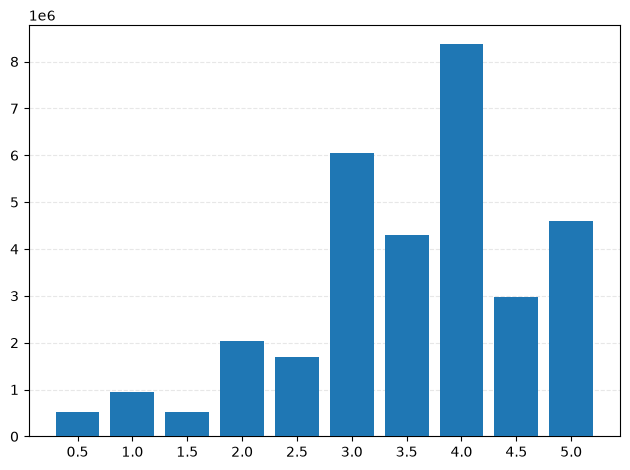

In [41]:
counts = ratings["rating"].value_counts().sort_index()

plt.bar(counts.index.astype(str), counts.values, zorder=3)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### Yearly volume and average rating
---

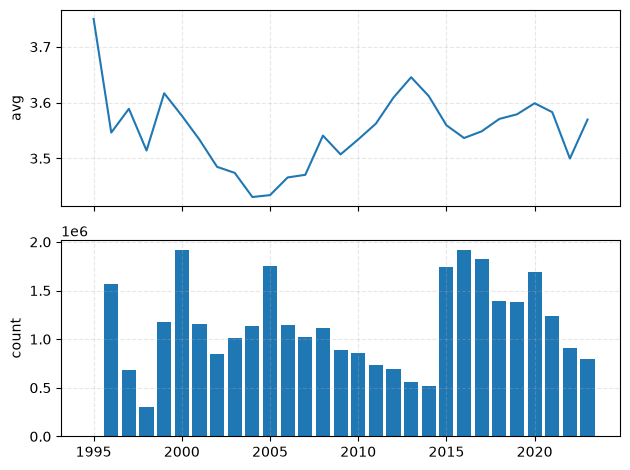

In [44]:
by_year = (
    ratings
    .groupby(ratings["timestamp"].dt.year)["rating"]
    .agg(mean="mean", n="count")
)

fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(by_year.index, by_year["mean"])
ax[0].set_ylabel("avg")
ax[1].bar(by_year.index, by_year["n"])
ax[1].set_ylabel("count")

for a in ax:
    a.grid(linestyle="--", alpha=0.3)
    
plt.tight_layout()
plt.show()

### Average ratings vs count
---

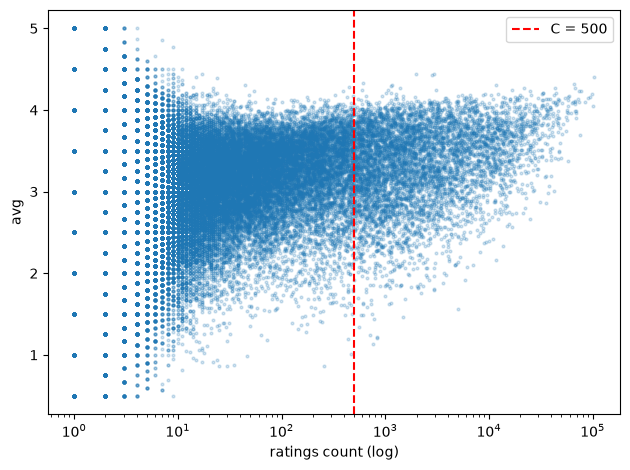

In [11]:
plt.scatter(stats["count"], stats["mean_rating"], s=4, alpha=0.2)
plt.xscale("log")
plt.axvline(C, color="red", linestyle="--", label=f"C = {C}")
plt.legend()
plt.xlabel("ratings count (log)")
plt.ylabel("avg")
plt.tight_layout()
plt.show()

### Long tail: ratings per movie and per user
---

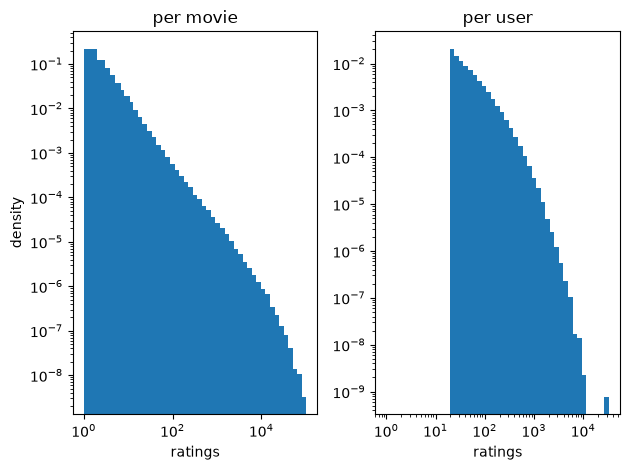

In [ ]:
def int_log_bins(s, n_bins=50):
    edges = np.logspace(
        0, 
        np.log10(s.max() + 1), 
        n_bins
    )
    
    return np.unique(
        np.round(edges)
        .astype(int)
    )

per_movie = ratings.groupby("movie_id").size()
per_user = ratings.groupby("user_id").size()

fig, ax = plt.subplots(1, 2)

for a, s, title in zip(
    ax, 
    [per_movie, per_user], 
    ["per movie", "per user"]
):
    a.hist(s, bins=int_log_bins(s), density=True)
    a.set_xscale("log")
    a.set_yscale("log")
    a.set_title(title)
    a.set_xlabel("ratings")

ax[0].set_ylabel("density")
plt.tight_layout()
plt.show()

### Average rating by genre
---

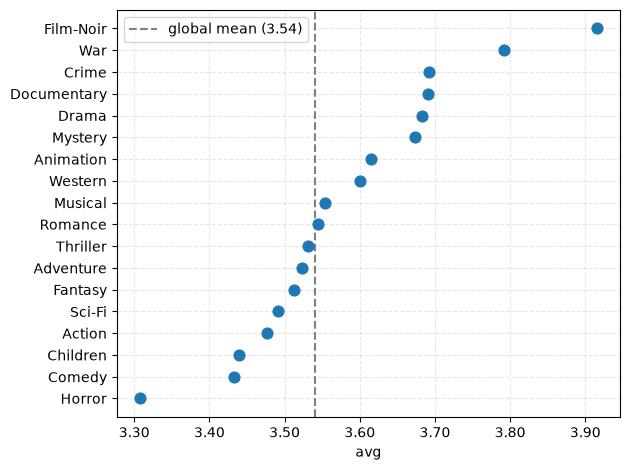

In [8]:
genres = stats[[
    "movie_id", 
    "total", 
    "count", 
    "genres"
]].copy()

genres["genres"] = genres["genres"].str.split("|")
genres = genres.explode("genres")
genres = genres[~genres["genres"].isin(["(no genres listed)", "IMAX"])]

by_genre = (
    genres
    .groupby("genres")
    .agg(total=("total", "sum"), n=("count", "sum"))
)

by_genre["mean_rating"] = by_genre["total"] / by_genre["n"]
by_genre = by_genre.sort_values("mean_rating")

fig, ax = plt.subplots()
ax.scatter(by_genre["mean_rating"], by_genre.index, s=60, zorder=3)

ax.axvline(
    global_mean, 
    color="gray", 
    linestyle="--",
    label=f"global mean ({global_mean:.2f})"
)

ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.set_xlabel("avg")
ax.grid(linestyle="--", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Most frequent tags
---

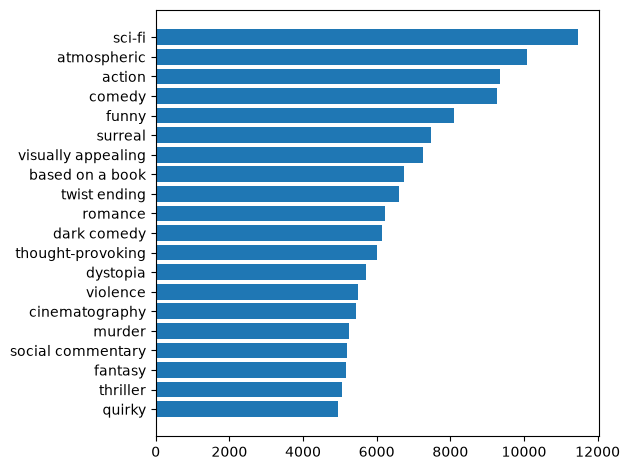

In [53]:
top_tags = tags["tag"].value_counts().head(20).sort_values()

plt.barh(top_tags.index, top_tags.values)
plt.tight_layout()
plt.show()

### Activity by hour
---

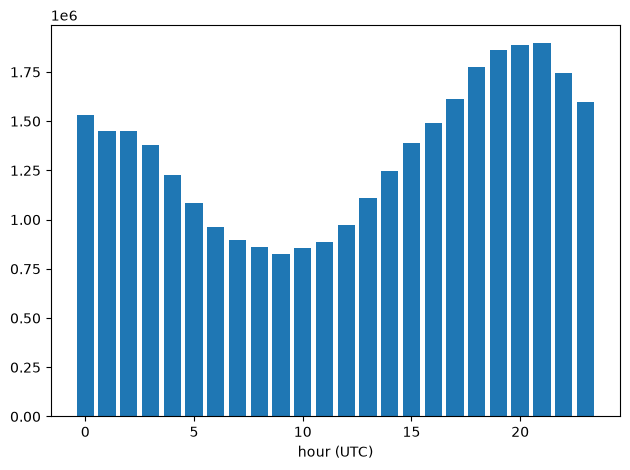

In [55]:
by_hour = ratings.groupby(ratings["timestamp"].dt.hour).size()

plt.bar(by_hour.index, by_hour.values)
plt.xlabel("hour (UTC)")
plt.tight_layout()
plt.show()

## Conclusions

- **Ratings skew positive.** The mean rating is about 3.54 and 4.0 is the most common value. Whole-star ratings are used more often than the neighbouring half-star ones, and low ratings (1.5 or below) are rare.
- **Small samples mislead.** Movies with only a few ratings have averages anywhere between 0.5 and 5.0, and the spread narrows as ratings accumulate. Ranking with a Bayesian average (shrunk toward the global mean, C = 500) is more reliable than a fixed minimum-count cutoff.
- **The data is extremely sparse and long-tailed.** Most movies have only a handful of ratings while a few have around 10^5. Every user has at least 20 ratings, but that comes from how the dataset was built, not from user behaviour.
- **Genre differences are moderate and partly structural.** Film-Noir and War rate highest (about 3.9 and 3.8) and Horror lowest (about 3.3). Survivorship bias likely plays a role, since old films that are still watched tend to be the ones that aged well. Genres overlap (a movie counts in each of its genres), so the values are not independent.
- **Time patterns are descriptive only.** The yearly average stays within a narrow range (about 3.43 to 3.65) and moves with the mix of users and films, so it does not show a change in taste. 1995 has very few ratings and 2023 is incomplete. Activity peaks around 19-21 UTC, but timestamps are when a rating was entered (often in bulk), and they mix time zones.
- **Tags add information that genres lack.** Subjective tags such as "atmospheric" or "twist ending" sit alongside genre tags, but they are very sparse: about 131k distinct tags, and even the most frequent one is used only around 11k times.